# Using Predictive Analytics to Identify Engagement Drivers in Instagram Reels
## Notebook 4 of 4: Evaluation and Deployment
**CRISP-DM phases 5 and 6**

### Recap of the project so far

| CRISP-DM phase | Notebook | Summary |
|---|---|---|
| 1. Business Understanding | 01 | Goal: find the content characteristics associated with above-baseline Reel performance. Success is judged by F1 and recall for the high-performing class |
| 2. Data Understanding | 01 | Roughly 30% of Reels are high-performing; engagement and reach measures describe the outcome; delivery features show almost no separation on their own; found Reels duplicated with conflicting labels and a placeholder hook value |
| 3. Data Preparation | 02 | Resolved the duplicates, cleaned and standardized the data, built engagement measures and interaction features, one-hot encoded categories, excluded outcome measures from the predictors |
| 4. Modeling | 03 | Logistic regression, k-NN, and a classification tree, each tuned and tested twice: content features only (Iteration 1), then with interaction features (Iteration 2) |

---
# Phase 5: Evaluation

## 5.1 Evaluate the results

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

results_df = pd.read_csv('../Data/model_results.csv')

metric_cols = ['accuracy', 'precision', 'recall', 'f1']
print("Final tuned models, evaluated on the validation set (metrics are for the high-performing class, except accuracy):\n")
print(results_df[['iteration', 'model', 'settings'] + metric_cols].round(3).to_string(index=False))

# Reference point: how well would a model that always predicts 'baseline' do?
first = results_df.iloc[0]
n_valid = int(first[['tn', 'fp', 'fn', 'tp']].sum())
share_baseline = (first['tn'] + first['fp']) / n_valid
print(f"\nValidation set: {n_valid} reels. Always predicting 'baseline' would be {share_baseline:.0%} accurate "
      f"but would find none of the high-performing reels.")

Final tuned models, evaluated on the validation set (metrics are for the high-performing class, except accuracy):

  iteration               model                        settings  accuracy  precision  recall    f1
Iteration 1 Logistic regression              penalty=l2, C=10.0     0.553      0.300   0.462 0.364
Iteration 1                k-NN                             k=1     0.638      0.357   0.385 0.370
Iteration 1 Classification tree max_depth=4, min_samples_leaf=5     0.574      0.267   0.308 0.286
Iteration 2 Logistic regression              penalty=l2, C=10.0     0.574      0.316   0.462 0.375
Iteration 2                k-NN                             k=1     0.638      0.357   0.385 0.370
Iteration 2 Classification tree max_depth=4, min_samples_leaf=5     0.638      0.250   0.154 0.190

Validation set: 47 reels. Always predicting 'baseline' would be 72% accurate but would find none of the high-performing reels.


In [2]:
# Best model in each iteration under the success criterion (F1 for the high-performing class)
for iteration, group in results_df.groupby('iteration', sort=False):
    best = group.sort_values('f1', ascending=False, kind='stable').iloc[0]
    print(f"{iteration}: best model by F1 = {best['model']}  "
          f"(F1 {best['f1']:.2f}, recall {best['recall']:.2f}, precision {best['precision']:.2f}, accuracy {best['accuracy']:.2f})")

# How much of a difference is real? One validation reel moves the scores a lot.
n_high = int(first['tp'] + first['fn'])
prevalence = n_high / n_valid
overall_best = results_df.sort_values('f1', ascending=False, kind='stable').iloc[0]
close_to_best = results_df[results_df['f1'] >= overall_best['f1'] - 0.05]

print(f"\nThe validation set has {n_high} high-performing reels, so finding one more changes recall by {1 / n_high:.0%}.")
print(f"Models within 0.05 F1 of the best ({overall_best['f1']:.2f}): "
      + ", ".join(f"{r.model} ({r.iteration})" for r in close_to_best.itertuples()))

# Reference points for the F1 of the high-performing class
print(f"\nReference F1 values (share of high-performing reels = {prevalence:.0%}):")
print(f"  Random guessing at the base rate: {prevalence:.2f}")
print(f"  Flagging every reel as high-performing: {2 * prevalence / (1 + prevalence):.2f} "
      f"(perfect recall, but precision of only {prevalence:.0%})")

Iteration 1: best model by F1 = k-NN  (F1 0.37, recall 0.38, precision 0.36, accuracy 0.64)
Iteration 2: best model by F1 = Logistic regression  (F1 0.38, recall 0.46, precision 0.32, accuracy 0.57)

The validation set has 13 high-performing reels, so finding one more changes recall by 8%.
Models within 0.05 F1 of the best (0.38): Logistic regression (Iteration 1), k-NN (Iteration 1), Logistic regression (Iteration 2), k-NN (Iteration 2)

Reference F1 values (share of high-performing reels = 28%):
  Random guessing at the base rate: 0.28
  Flagging every reel as high-performing: 0.43 (perfect recall, but precision of only 28%)


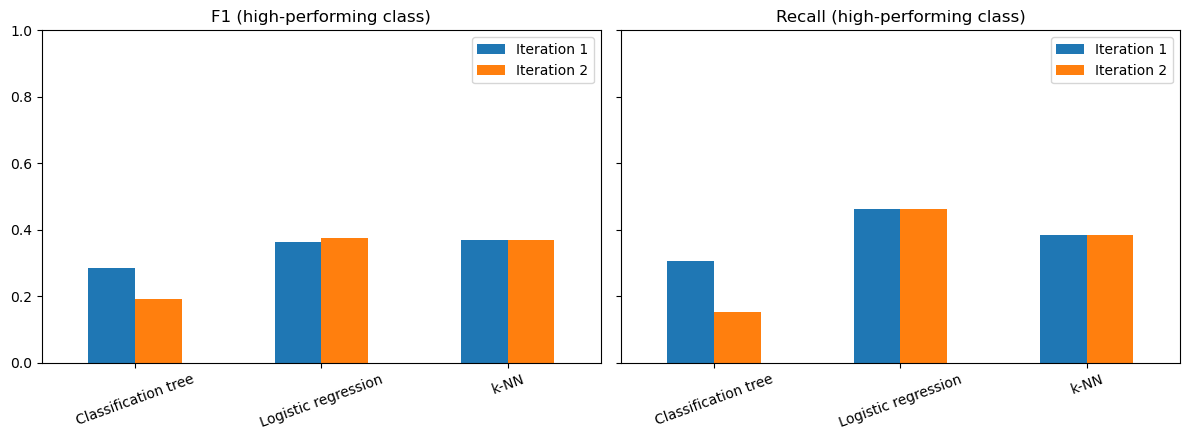

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, metric, title in zip(axes, ['f1', 'recall'], ['F1 (high-performing class)', 'Recall (high-performing class)']):
    results_df.pivot(index='model', columns='iteration', values=metric).plot(kind='bar', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=20)
    ax.legend(title='')

plt.tight_layout()
plt.show()

In [4]:
# What each final model got right and wrong on the validation set
confusion = results_df[['iteration', 'model', 'tp', 'fn', 'fp', 'tn']].rename(columns={
    'tp': 'high found (TP)', 'fn': 'high missed (FN)',
    'fp': 'baseline flagged as high (FP)', 'tn': 'baseline correct (TN)'
})
confusion

,iteration,model,high found (TP),high missed (FN),baseline flagged as high (FP),baseline correct (TN)
0,Iteration 1,Logistic regression,6,7,14,20
1,Iteration 1,k-NN,5,8,9,25
2,Iteration 1,Classification tree,4,9,11,23
3,Iteration 2,Logistic regression,6,7,13,21
4,Iteration 2,k-NN,5,8,9,25
5,Iteration 2,Classification tree,2,11,6,28


### Assessment against the success criteria

**Technical criterion** (identify high-performing Reels better than chance, judged by F1 and recall for the high-performing class):
- Accuracy and the F1/recall for the high-performing class tell different stories. k-NN in particular can post a higher accuracy by mostly predicting the majority (baseline) class while finding fewer of the high-performing Reels. Under the stated criterion, F1 and recall for the high-performing class are the deciding metrics.
- The validation set is small, so differences between models are mostly noise: one reel moves recall by several points. When models are within about 0.05 F1 of each other (see the summary above), they should be treated as tied.
- Compare the F1 values with the reference points printed above. The models are only modestly better than random guessing, and a model that flags every Reel as high-performing would score a higher F1 (but would be useless, since it has no discrimination). Overall predictive power is therefore **modest**: content features alone explain only part of Reel performance, and external factors such as timing, audience behavior, and algorithmic distribution likely play a significant role.
- The classification tree is the exploratory model and is not recommended as a final model.

**Business criterion** (surface content patterns a team could test): the rate tables in Notebook 1 and the logistic regression coefficients in Notebook 3 identify candidate patterns (specific craft categories, reel structures, and hook types with higher or lower rates than average) to test in future content. The delivery features (result shown first, voice, audio, POV) showed almost no separation on their own. Adding interaction features tested whether *combinations* of content choices matter more than isolated features; compare the two iterations in the table above to see how much they helped.

**Decision:** because no model is clearly better and all are weak, prefer the **logistic regression** for decision support. It is the most interpretable, so a team can see which features push the estimate up or down, and its recommendations should be treated as hypotheses to test, not predictions to rely on.

## 5.2 Review the process

### Business Understanding
Dataset scope strongly affects model performance. Even the strongest model struggled to classify high-performing Reels consistently, which suggests that important influences on performance were not captured. A larger dataset with more Reels and additional variables (timing, audience behavior, platform distribution) would likely improve results.

### Data Understanding
- Duplicate checks must use identifying fields, not whole rows. Checking for identical rows found nothing, but checking URLs revealed 12 Reels that appeared twice with opposite performance labels. These contradictory labels would have added noise to the target and let identical Reels fall into both the training and validation sets.
- A placeholder value (`Choose from...`) in a category column was also found, which shows why category value counts should be reviewed before encoding.
- Interactions between variables should be examined early. The first exploration looked mainly at single features. In this version of the project the interaction heatmaps are part of Notebook 1 (section 2.4f).
- A correlation matrix only measures how strongly numeric variables move together, and most predictors here are categorical or binary. Rate tables and heatmaps are better suited to category combinations. Chi-square tests could also be used to check whether categorical associations are statistically significant without building a model.
- The age of the Reel at collection (`days_since_posted`) is strongly associated with the target, so recency is a confounder.

### Data Preparation
- Revisiting the original data to build interaction features (craft x hook, craft x structure, hook x structure) and adding them to the predictors was a worthwhile test of whether combinations of features matter. The comparison between iterations in section 5.1 shows how much they helped.
- Outcome measures (views, likes, comments, engagement rate, views per follower) were kept out of the predictors to avoid data leakage.
- Very rare indicator columns were dropped because they are too sparse to learn from.

### Modeling
- Selecting hyperparameters by accuracy was misleading because of class imbalance; switching to F1 for the high-performing class gave a better basis for choosing between settings.
- Hyperparameters were tuned on the same validation set used for reporting, and the validation set is small, so the reported scores are noisy and likely optimistic. The tuning can also land on unstable settings (for example `k=1` in k-NN). Differences of a few points between models should not be over-interpreted.

### Evaluation
Judging models by one consistent criterion (F1 and recall for the high-performing class) matters. A model that looks best on accuracy can be the weakest at the task the business cares about.

## 5.3 Next steps
1. Collect more Reels and add timing, audience, and distribution variables.
2. Replace the single train/validation split with stratified cross-validation, and keep a final untouched test set, so tuning and reporting use different data.
3. Test the strongest interaction patterns with controlled content experiments instead of relying only on observational data.
4. Use chi-square tests or similar checks to confirm which category associations are statistically meaningful.

---
# Phase 6: Deployment

## 6.1 Deployment plan
The selected model (the tuned logistic regression, preferred for its interpretability) would be implemented as a **decision-support tool** for a marketing or social media team, not as a fully automated decision-maker. It would estimate the likelihood that a planned Reel achieves above-baseline performance from its content characteristics (hook category, reel structure, craft category, presentation choices, and the interaction terms identified in the analysis). This fits the business goal of helping creators and social media teams make better-informed content decisions before publishing.

**Usage guidelines.** Because overall predictive power is modest, the model should be used to prioritize ideas to test, compare candidate Reel concepts, and support planning discussions. It should not be used to approve or reject content on its own. The most practical use is helping a content team decide which combinations of hooks, structures, and presentation elements are most promising to test next.

## 6.2 Monitoring and maintenance
- **Collect new data.** After Reels are posted, record engagement and creator-relative performance so the dataset keeps growing.
- **Retrain on a schedule.** Retrain monthly or quarterly with the newer examples to reflect shifts in audience behavior. This matters here because interactions between variables improved performance while overall predictive strength stayed limited, which suggests that trends on Instagram change over time.
- **Add missing factors.** Update the model as variables that influence performance but were not captured here (timing, audience behavior, distribution) become available.
- **Track performance.** Monitor F1 and recall for the high-performing class on newly labeled Reels, and investigate if they fall.

## 6.3 Final report: highlights and lowlights
**Highlights**
- Careful data-quality checks found conflicting duplicate labels and a placeholder value that would otherwise have distorted the target and the validation scores.
- A creator-relative definition of performance and an imbalance-aware evaluation criterion (F1 and recall for the high-performing class) kept the results honest.
- The project followed an iterative CRISP-DM process: lessons from Evaluation led back to Data Understanding, Data Preparation, and a second round of Modeling.

**Lowlights**
- Even after feature engineering and interaction analysis, the models showed only modest predictive power. None clearly distinguished high-performing from baseline Reels, which means the content features in the dataset explain only part of Reel performance.
- The small dataset limits how far the results can be trusted or generalized.

## 6.4 Review the project
What went well: a clear, creator-relative definition of performance; thorough data-quality checks; a consistent evaluation criterion for imbalanced classes; and an iteration that tested a specific hypothesis (interactions matter). What to do differently: check for duplicates by identifier from the start, use cross-validation, and collect a larger and richer dataset.